# Machine Learning-Based Customer Churn Prediction
## Telco Customer Churn Dataset


## 1. Environment Setup and Dependencies

In [1]:
# Ignore non-critical warnings
import warnings
warnings.filterwarnings("ignore")

# Core libraries
import os
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc
)

from sklearn.inspection import permutation_importance

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")
print("Environment setup completed successfully.")

Environment setup completed successfully.


## 2. Import the Kaggle Dataset

In [2]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Kaggle dataset
dataset_name = "blastchar/telco-customer-churn"

# The dataset contains the Telco Customer Churn CSV.
# An empty path lets KaggleHub resolve the dataset file where supported.
file_path = ""

try:
    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        dataset_name,
        file_path
    )
except Exception:
    # Fallback to the known CSV filename
    file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        dataset_name,
        file_path
    )

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print(df.head())

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dataset loaded successfully.
Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           N

## 3. Initial Dataset Inspection

In [3]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nFirst 5 records:")
print(df.head())

print("\nLast 5 records:")
print(df.tail())

Dataset dimensions: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,Data Type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



First 5 records:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No  

## 4. Data Quality Checks and Preprocessing

In [4]:
# Work on a copy so the imported dataset remains available
data = df.copy()

# Standardise column names by removing accidental leading/trailing spaces
data.columns = data.columns.str.strip()

# Remove leading/trailing spaces from string values
object_columns = data.select_dtypes(include="object").columns
for col in object_columns:
    data[col] = data[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

# Convert TotalCharges to numeric.
# Invalid blank values are converted to NaN and handled below.
if "TotalCharges" in data.columns:
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

# Replace blank strings with missing values
data = data.replace(r"^\s*$", np.nan, regex=True)

# Check duplicate rows
duplicate_count = data.duplicated().sum()

# Check missing values before treatment
missing_before = data.isna().sum().sort_values(ascending=False)
missing_before = missing_before[missing_before > 0]

print("Duplicate rows:", duplicate_count)
print("\nMissing values before treatment:")
display(missing_before.to_frame("Missing Values"))

# CustomerID is an identifier and should not be used as a predictive feature
if "customerID" in data.columns:
    data = data.drop(columns=["customerID"])

# Remove exact duplicate observations
data = data.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", data.shape)

Duplicate rows: 0

Missing values before treatment:


,Missing Values
TotalCharges,11


Shape after duplicate removal: (7021, 20)


### 4.1 Missing Values, Target Preparation and Data Consistency

In [5]:
# Handle missing values and prepare the target variable

# TotalCharges contains blank values for some customers.
# These are converted to numeric and missing values are replaced with 0.
if "TotalCharges" in data.columns:
    data["TotalCharges"] = pd.to_numeric(
        data["TotalCharges"],
        errors="coerce"
    )

    data["TotalCharges"] = data["TotalCharges"].fillna(0)

# Target variable
target = "Churn"

# Remove rows with missing target values, if any
data = data.dropna(subset=[target]).reset_index(drop=True)

# Convert Churn into binary values
data[target] = data[target].map({
    "No": 0,
    "Yes": 1
})

# Check for unexpected target values
if data[target].isna().any():
    raise ValueError("Unexpected values found in the Churn target.")

# Identify numerical and categorical predictors
numeric_features = data.drop(columns=[target]).select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = data.drop(columns=[target]).select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

# Check missing values after treatment
missing_after = data.isna().sum().sort_values(ascending=False)
missing_after = missing_after[missing_after > 0]

print("\nMissing values after treatment:")

if len(missing_after) == 0:
    print("No missing values remain.")
else:
    display(missing_after.to_frame("Missing Values"))

# Target distribution
print("\nTarget distribution:")

target_distribution = data[target].value_counts().sort_index()

display(
    target_distribution.rename({
        0: "No Churn",
        1: "Churn"
    }).to_frame("Count")
)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Missing values after treatment:
No missing values remain.

Target distribution:


,Count
Churn,
No Churn,5164
Churn,1857


### 4.2 Preprocessing Summary

In [6]:
# Create a compact preprocessing summary for reporting
preprocessing_summary = pd.DataFrame({
    "Preprocessing Step": [
        "Duplicate check",
        "Identifier removal",
        "String cleaning",
        "TotalCharges numeric conversion",
        "Missing target treatment",
        "Categorical variable handling",
        "Numerical variable handling",
        "Class imbalance handling",
        "Train-test split"
    ],
    "Action": [
        f"Checked and removed {duplicate_count} duplicate rows",
        "customerID excluded from modelling",
        "Leading/trailing spaces removed",
        "Converted to numeric with invalid entries as missing",
        "Rows with missing Churn removed",
        "One-hot encoding within modelling pipeline",
        "Median imputation and standardisation within modelling pipeline",
        "Class weights used during model training where applicable",
        "Stratified 80:20 split"
    ]
})

display(preprocessing_summary)

print("Final cleaned dataset shape:", data.shape)

,Preprocessing Step,Action
0,Duplicate check,Checked and removed 0 duplicate rows
1,Identifier removal,customerID excluded from modelling
2,String cleaning,Leading/trailing spaces removed
3,TotalCharges numeric conversion,Converted to numeric with invalid entries as m...
4,Missing target treatment,Rows with missing Churn removed
5,Categorical variable handling,One-hot encoding within modelling pipeline
6,Numerical variable handling,Median imputation and standardisation within m...
7,Class imbalance handling,Class weights used during model training where...
8,Train-test split,Stratified 80:20 split


Final cleaned dataset shape: (7021, 20)


## 5. Exploratory Data Analysis (EDA)

### 5.1 Descriptive Statistics

In [7]:
print("Numerical descriptive statistics:")
display(data.describe().T)

print("\nCategorical variable summary:")
categorical_summary = pd.DataFrame({
    "Unique Values": data[categorical_features].nunique(),
    "Missing Values": data[categorical_features].isna().sum()
})
display(categorical_summary)

Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7021.0,0.162512,0.368947,0.00,0.00,0.00,0.0,1.00
tenure,7021.0,32.469449,24.534965,0.00,9.00,29.00,55.0,72.00
MonthlyCharges,7021.0,64.851894,30.069001,18.25,35.75,70.40,89.9,118.75
TotalCharges,7021.0,2286.765026,2266.855057,0.00,403.35,1400.55,3801.7,8684.80
Churn,7021.0,0.264492,0.441094,0.00,0.00,0.00,1.0,1.00



Categorical variable summary:


,Unique Values,Missing Values
gender,2,0
Partner,2,0
Dependents,2,0
PhoneService,2,0
MultipleLines,3,0
InternetService,3,0
OnlineSecurity,3,0
OnlineBackup,3,0
DeviceProtection,3,0
TechSupport,3,0


### 5.2 Overall Churn Distribution

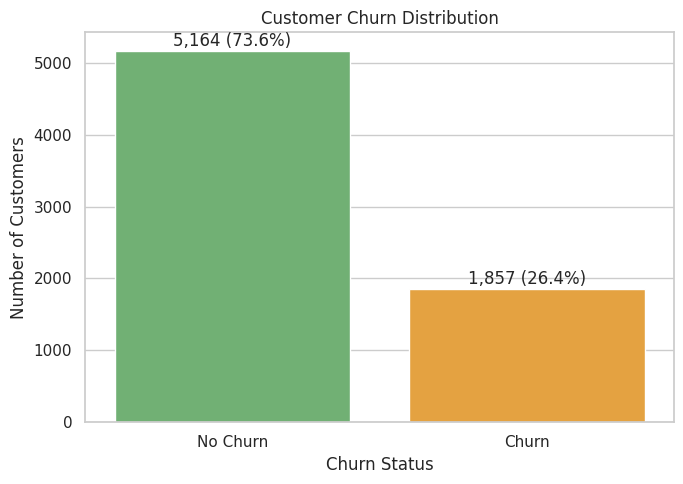

In [8]:
churn_counts = data[target].value_counts().sort_index()

churn_labels = ["No Churn", "Churn"]

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=churn_labels,
    y=[churn_counts.get(0, 0), churn_counts.get(1, 0)],
    palette=["#66BB6A", "#FFA726"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

total = len(data)

for i, value in enumerate([churn_counts.get(0, 0), churn_counts.get(1, 0)]):
    ax.text(
        i,
        value + total * 0.01,
        f"{value:,} ({value/total:.1%})",
        ha="center"
    )

plt.tight_layout()
plt.show()

### 5.3 Numerical Variables and Churn

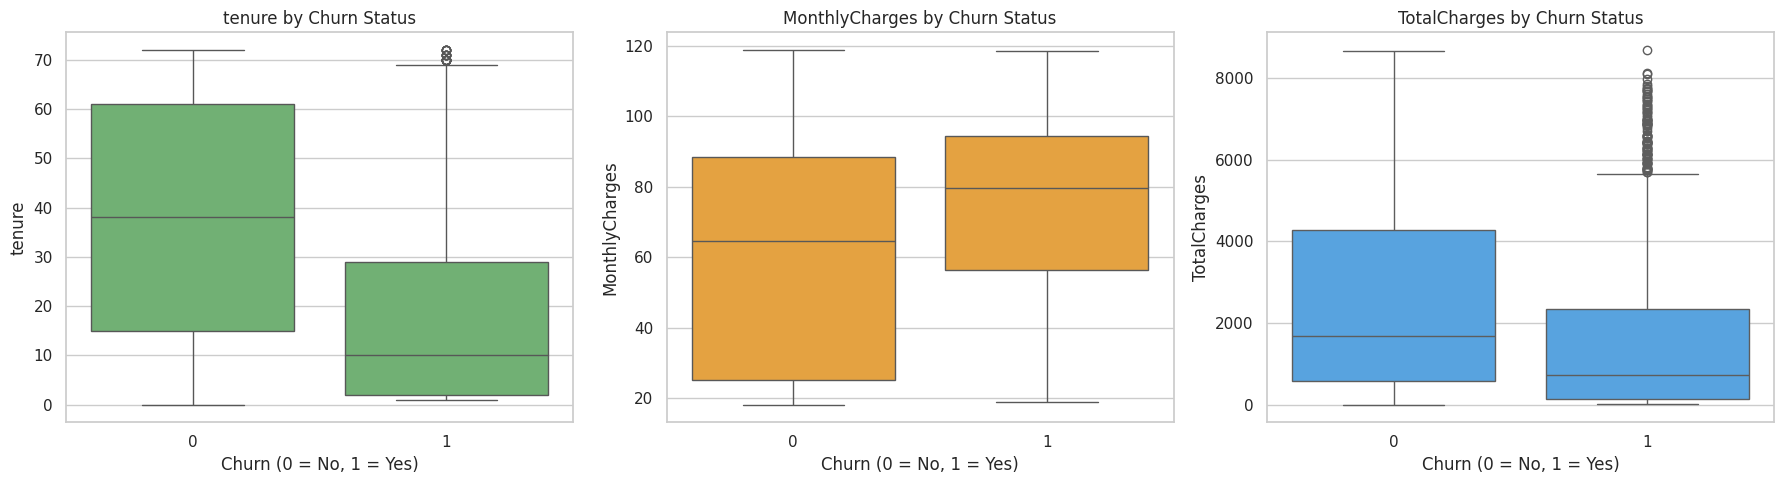

tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
0      37.64   38.0          61.34   64.5      2554.81  1683.0
1      18.09   10.0          74.60   79.7      1541.38   713.1

In [9]:
# Key numerical variables in the Telco dataset
eda_numeric = [
    col for col in ["tenure", "MonthlyCharges", "TotalCharges"]
    if col in data.columns
]

fig, axes = plt.subplots(
    1,
    len(eda_numeric),
    figsize=(6 * len(eda_numeric), 5)
)

if len(eda_numeric) == 1:
    axes = [axes]

# Colours for the three numerical variables
plot_colors = ["#66BB6A", "#FFA726", "#42A5F5"]

for ax, col, color in zip(axes, eda_numeric, plot_colors):
    sns.boxplot(
        data=data,
        x=target,
        y=col,
        ax=ax,
        color=color
    )

    ax.set_title(f"{col} by Churn Status")
    ax.set_xlabel("Churn (0 = No, 1 = Yes)")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

# Mean and median comparison
display(
    data.groupby(target)[eda_numeric]
    .agg(["mean", "median"])
    .round(2)
)

### 5.4 Contract Type and Churn

Churn,No Churn (%),Churn (%)
Contract,,
Month-to-month,57.36,42.64
One year,88.73,11.27
Two year,97.17,2.83


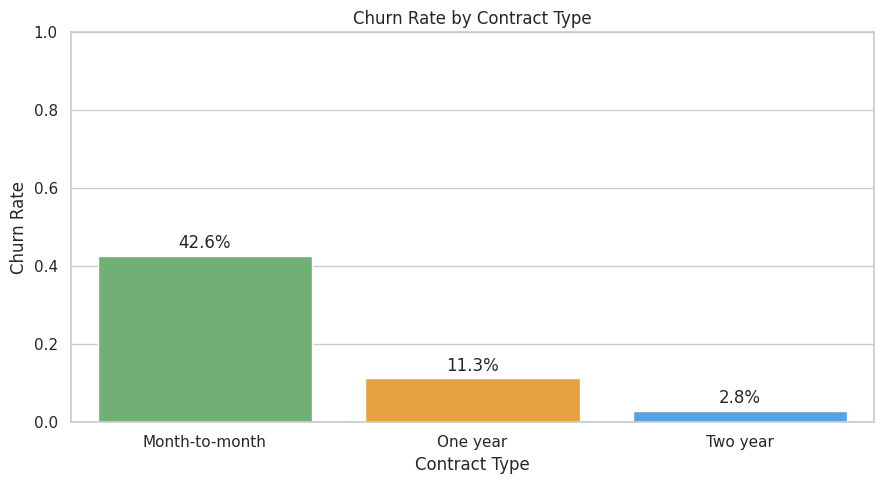

In [10]:
if "Contract" in data.columns:
    contract_churn = pd.crosstab(
        data["Contract"], data[target], normalize="index"
    ) * 100

    contract_churn = contract_churn.rename(
        columns={0: "No Churn (%)", 1: "Churn (%)"}
    )

    display(contract_churn.round(2))

    plt.figure(figsize=(9, 5))

    ax = sns.barplot(
        data=data,
        x="Contract",
        y=target,
        estimator=np.mean,
        errorbar=None,
        palette=["#66BB6A", "#FFA726", "#42A5F5"]
    )

    plt.title("Churn Rate by Contract Type")
    plt.xlabel("Contract Type")
    plt.ylabel("Churn Rate")
    plt.ylim(0, 1)

    for i, contract in enumerate(data["Contract"].dropna().unique()):
        rate = data.loc[data["Contract"] == contract, target].mean()
        plt.text(
            i,
            rate + 0.02,
            f"{rate:.1%}",
            ha="center"
        )

    plt.tight_layout()
    plt.show()

### 5.5 Internet Service and Churn

Churn,No Churn (%),Churn (%)
InternetService,,
DSL,81.11,18.89
Fiber optic,58.22,41.78
No,92.79,7.21


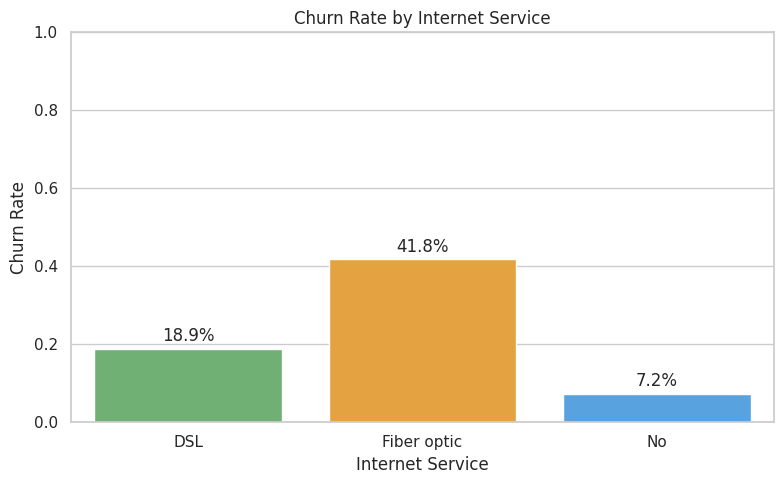

In [11]:
if "InternetService" in data.columns:
    internet_churn = pd.crosstab(
        data["InternetService"], data[target], normalize="index"
    ) * 100

    internet_churn = internet_churn.rename(
        columns={0: "No Churn (%)", 1: "Churn (%)"}
    )

    display(internet_churn.round(2))

    plt.figure(figsize=(8, 5))

    ax = sns.barplot(
        data=data,
        x="InternetService",
        y=target,
        estimator=np.mean,
        errorbar=None,
        palette=["#66BB6A", "#FFA726", "#42A5F5"]
    )

    plt.title("Churn Rate by Internet Service")
    plt.xlabel("Internet Service")
    plt.ylabel("Churn Rate")
    plt.ylim(0, 1)

    for i, category in enumerate(data["InternetService"].dropna().unique()):
        rate = data.loc[
            data["InternetService"] == category, target
        ].mean()

        plt.text(
            i,
            rate + 0.02,
            f"{rate:.1%}",
            ha="center"
        )

    plt.tight_layout()
    plt.show()

### 5.6 Payment Method and Churn

Churn,No Churn (%),Churn (%)
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.85,45.15
Mailed check,81.08,18.92


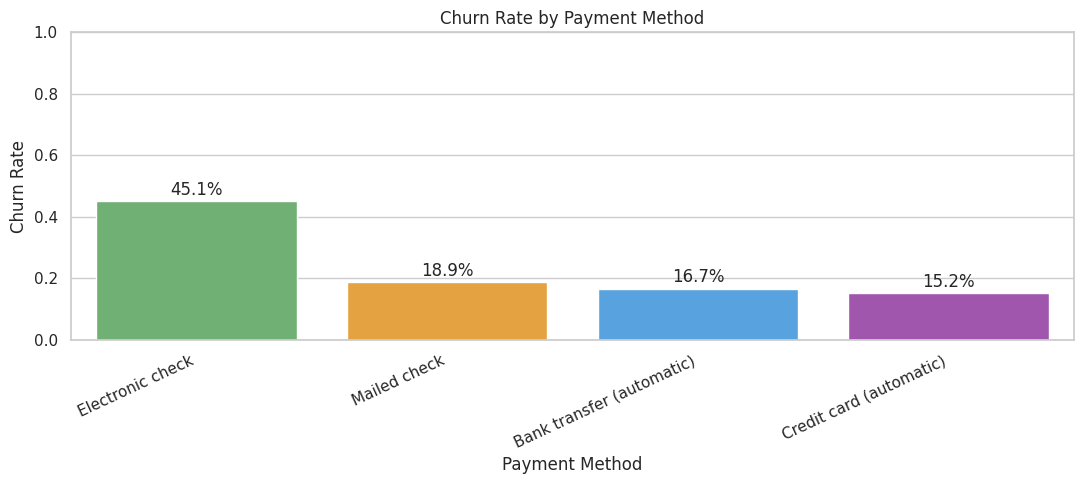

In [12]:
if "PaymentMethod" in data.columns:
    payment_churn = pd.crosstab(
        data["PaymentMethod"], data[target], normalize="index"
    ) * 100

    payment_churn = payment_churn.rename(
        columns={0: "No Churn (%)", 1: "Churn (%)"}
    )

    display(payment_churn.round(2))

    plt.figure(figsize=(11, 5))

    ax = sns.barplot(
        data=data,
        x="PaymentMethod",
        y=target,
        estimator=np.mean,
        errorbar=None,
        palette=["#66BB6A", "#FFA726", "#42A5F5", "#AB47BC"]
    )

    plt.title("Churn Rate by Payment Method")
    plt.xlabel("Payment Method")
    plt.ylabel("Churn Rate")
    plt.xticks(rotation=25, ha="right")
    plt.ylim(0, 1)

    for i, category in enumerate(data["PaymentMethod"].dropna().unique()):
        rate = data.loc[
            data["PaymentMethod"] == category, target
        ].mean()

        plt.text(
            i,
            rate + 0.02,
            f"{rate:.1%}",
            ha="center"
        )

    plt.tight_layout()
    plt.show()

### 5.7 Customer Demographics and Churn

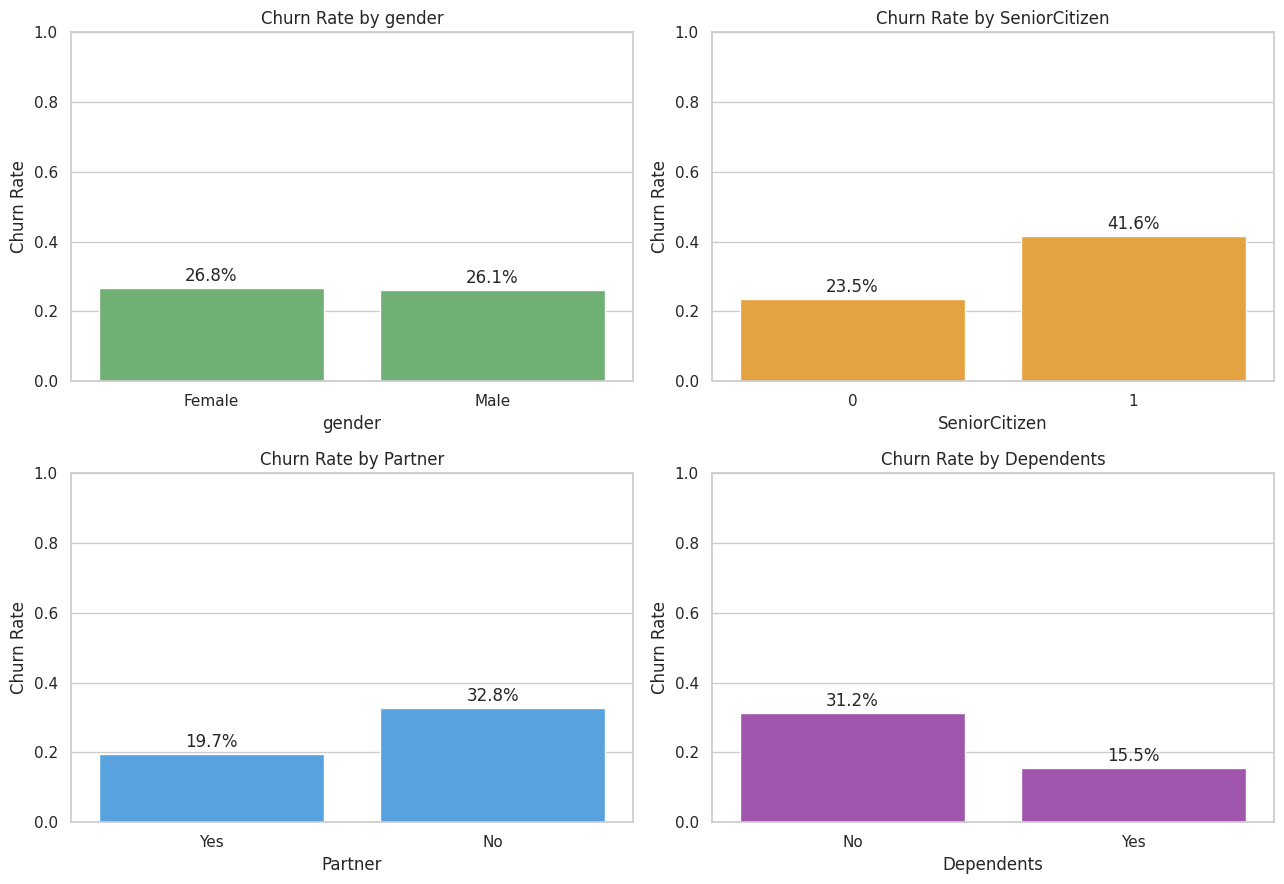

In [13]:
demographic_features = [
    col for col in ["gender", "SeniorCitizen", "Partner", "Dependents"]
    if col in data.columns
]

fig, axes = plt.subplots(
    2, 2, figsize=(13, 9)
)

axes = axes.flatten()

# Colours for the four demographic variables
demographic_colors = [
    "#66BB6A",  # Green
    "#FFA726",  # Orange
    "#42A5F5",  # Light blue
    "#AB47BC"   # Purple
]

for ax, col, color in zip(axes, demographic_features, demographic_colors):
    sns.barplot(
        data=data,
        x=col,
        y=target,
        estimator=np.mean,
        errorbar=None,
        color=color,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Churn Rate")
    ax.set_ylim(0, 1)

    # Add percentage labels
    categories = data[col].dropna().unique()

    for i, category in enumerate(categories):
        rate = data.loc[data[col] == category, target].mean()

        ax.text(
            i,
            rate + 0.02,
            f"{rate:.1%}",
            ha="center"
        )

for ax in axes[len(demographic_features):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 5.8 Selected Service Features and Churn

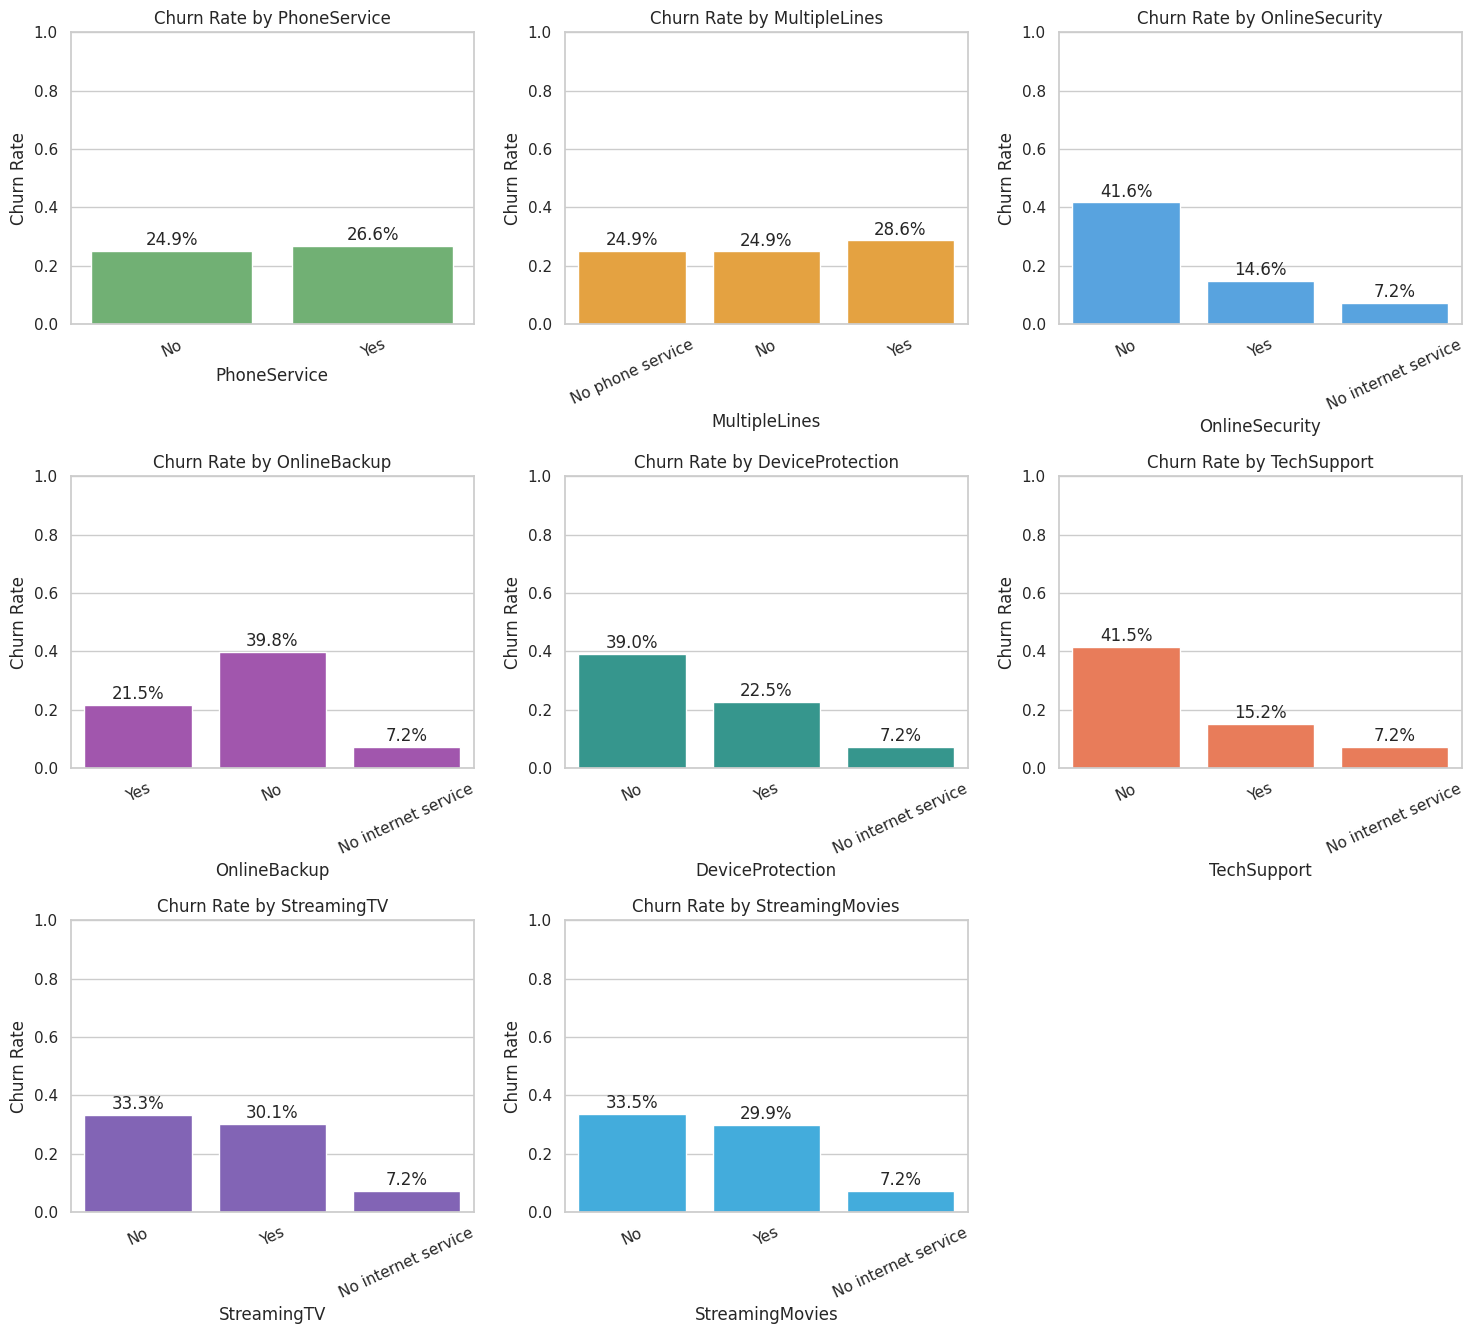

In [14]:
service_features = [
    col for col in [
        "PhoneService", "MultipleLines", "OnlineSecurity",
        "OnlineBackup", "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ] if col in data.columns
]

n = len(service_features)

cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(15, 4.5 * rows)
)

axes = np.array(axes).reshape(-1)

# Colours for the service variables
service_colors = [
    "#66BB6A",  # Green
    "#FFA726",  # Orange
    "#42A5F5",  # Light blue
    "#AB47BC",  # Purple
    "#26A69A",  # Teal
    "#FF7043",  # Deep orange
    "#7E57C2",  # Violet
    "#29B6F6"   # Sky blue
]

for ax, col, color in zip(axes, service_features, service_colors):

    sns.barplot(
        data=data,
        x=col,
        y=target,
        estimator=np.mean,
        errorbar=None,
        color=color,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Churn Rate")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)

    # Add churn-rate percentages above bars
    categories = data[col].dropna().unique()

    for i, category in enumerate(categories):
        rate = data.loc[
            data[col] == category, target
        ].mean()

        ax.text(
            i,
            rate + 0.02,
            f"{rate:.1%}",
            ha="center"
        )

# Hide unused subplots
for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 5.9 Correlation Analysis for Numerical Variables

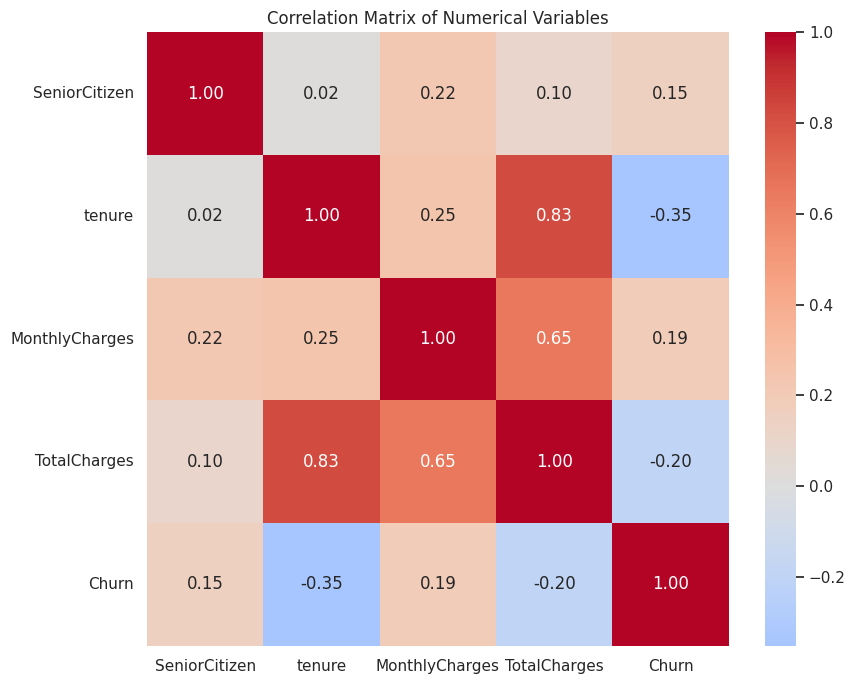

Correlation with Churn:


,Correlation with Churn
MonthlyCharges,0.194508
SeniorCitizen,0.151619
TotalCharges,-0.197198
tenure,-0.351508


In [15]:
# Correlation is used here as an EDA diagnostic, not as the main predictive method.
numeric_for_corr = data.select_dtypes(include=np.number)

plt.figure(figsize=(9, 7))
sns.heatmap(
    numeric_for_corr.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

print("Correlation with Churn:")
display(
    numeric_for_corr.corr()[target]
    .drop(target)
    .sort_values(ascending=False)
    .to_frame("Correlation with Churn")
)

### 5.10 Automated EDA Insight Table

In [16]:
# Generate concise, data-driven insights from key categorical variables
insight_rows = []

for col in [
    "Contract", "InternetService", "PaymentMethod",
    "OnlineSecurity", "TechSupport", "PaperlessBilling"
]:
    if col in data.columns:
        rates = data.groupby(col)[target].mean().sort_values(ascending=False)
        highest_category = rates.index[0]
        lowest_category = rates.index[-1]

        insight_rows.append({
            "Variable": col,
            "Highest Churn Category": highest_category,
            "Highest Churn Rate": rates.iloc[0],
            "Lowest Churn Category": lowest_category,
            "Lowest Churn Rate": rates.iloc[-1]
        })

eda_insights = pd.DataFrame(insight_rows)
display(eda_insights.style.format({
    "Highest Churn Rate": "{:.1%}",
    "Lowest Churn Rate": "{:.1%}"
}))

print("EDA completed. The tables and visualisations above provide evidence for identifying customer, service and account characteristics associated with churn.")

,Variable,Highest Churn Category,Highest Churn Rate,Lowest Churn Category,Lowest Churn Rate
0,Contract,Month-to-month,42.6%,Two year,2.8%
1,InternetService,Fiber optic,41.8%,No,7.2%
2,PaymentMethod,Electronic check,45.1%,Credit card (automatic),15.2%
3,OnlineSecurity,No,41.6%,No internet service,7.2%
4,TechSupport,No,41.5%,No internet service,7.2%
5,PaperlessBilling,Yes,33.4%,No,16.3%


EDA completed. The tables and visualisations above provide evidence for identifying customer, service and account characteristics associated with churn.


## 6. Prepare Data for Machine Learning

In [17]:
# Separate predictors and target
X = data.drop(columns=[target])
y = data[target]

# Identify feature types again after all cleaning
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Stratified split preserves the churn proportion in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).rename({
    0: "No Churn",
    1: "Churn"
}).to_frame("Proportion"))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).rename({
    0: "No Churn",
    1: "Churn"
}).to_frame("Proportion"))

Training set: (5616, 19)
Testing set: (1405, 19)

Training target distribution:


,Proportion
Churn,
No Churn,0.735577
Churn,0.264423



Testing target distribution:


,Proportion
Churn,
No Churn,0.735231
Churn,0.264769


### 6.1 Preprocessing Pipeline

In [18]:
# Numeric preprocessing:
# - median imputation prevents missing numeric values from causing model errors
# - standardisation supports scale-sensitive models such as Logistic Regression and SVM

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# - most-frequent imputation handles any missing categories
# - one-hot encoding converts categories into model-ready numerical variables
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 7. Machine Learning Model Development

In [19]:
# Define selected classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Support Vector Machine": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

print("Models prepared:")
for name in pipelines:
    print("-", name)

Models prepared:
- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine


### 7.1 Train All Models

In [20]:
results = []
fitted_models = {}
predictions = {}
probabilities = {}

for name, pipeline in pipelines.items():
    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

print("All models trained successfully.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Support Vector Machine...
All models trained successfully.


## 8. Model Evaluation and Comparison

In [21]:
results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-Score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)

print("Model comparison completed.")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.742,0.508,0.780,0.615,0.840
1,Random Forest,0.784,0.581,0.667,0.621,0.837
2,Support Vector Machine,0.762,0.535,0.774,0.633,0.825
3,Decision Tree,0.738,0.504,0.734,0.597,0.807


Model comparison completed.


### 8.1 Classification Reports

In [22]:
for name in fitted_models:
    print("=" * 80)
    print(name)
    print("=" * 80)
    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=["No Churn", "Churn"],
            digits=3,
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

    No Churn      0.902     0.728     0.806      1033
       Churn      0.508     0.780     0.615       372

    accuracy                          0.742      1405
   macro avg      0.705     0.754     0.710      1405
weighted avg      0.797     0.742     0.755      1405

Decision Tree
              precision    recall  f1-score   support

    No Churn      0.885     0.740     0.806      1033
       Churn      0.504     0.734     0.597       372

    accuracy                          0.738      1405
   macro avg      0.694     0.737     0.702      1405
weighted avg      0.784     0.738     0.751      1405

Random Forest
              precision    recall  f1-score   support

    No Churn      0.873     0.827     0.849      1033
       Churn      0.581     0.667     0.621       372

    accuracy                          0.784      1405
   macro avg      0.727     0.747     0.735      1405
weighted avg      0.796   

## 9. Confusion Matrices

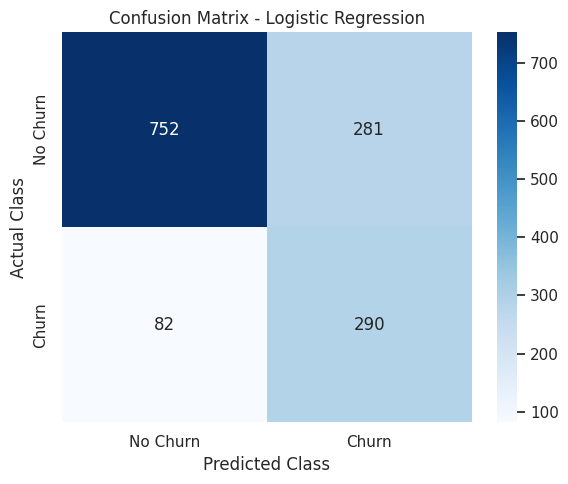

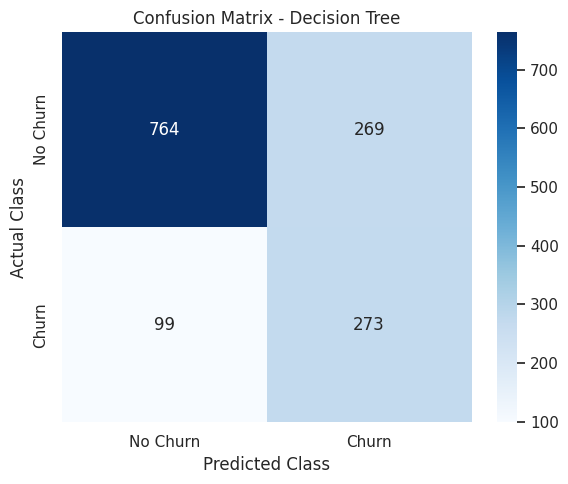

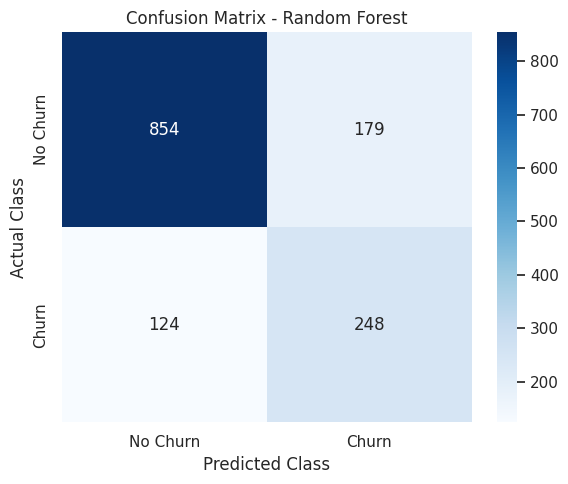

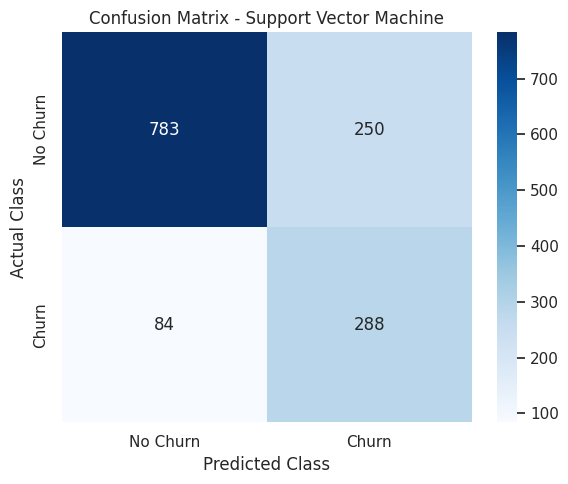

In [23]:
for name in fitted_models:
    cm = confusion_matrix(y_test, predictions[name])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

## 10. ROC Curves

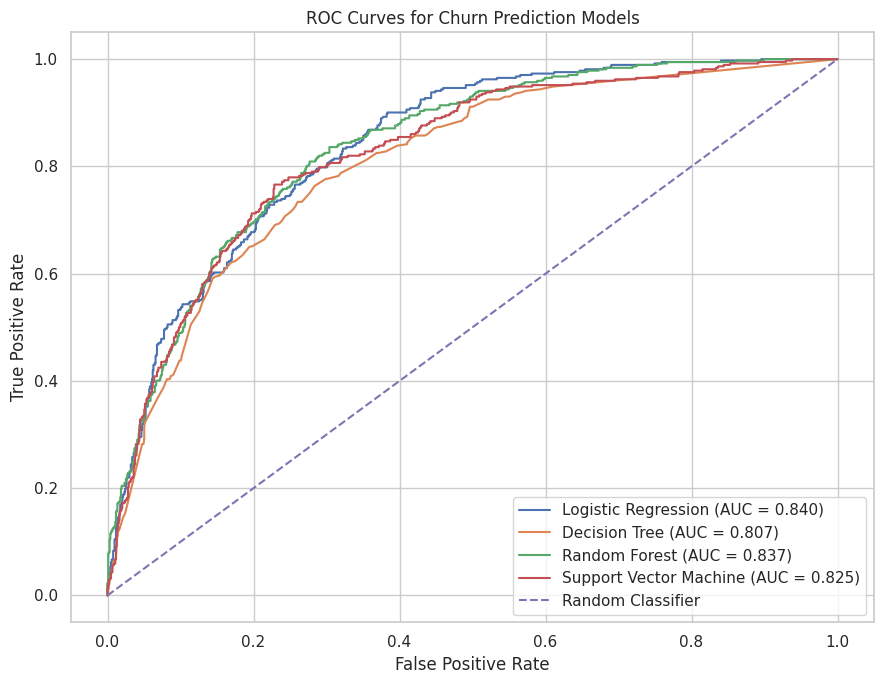

In [24]:
plt.figure(figsize=(9, 7))

for name in fitted_models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curves for Churn Prediction Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Feature Importance

,Feature,Importance
1,num__tenure,0.127957
3,num__TotalCharges,0.115605
36,cat__Contract_Month-to-month,0.107239
2,num__MonthlyCharges,0.086767
38,cat__Contract_Two year,0.053608
18,cat__OnlineSecurity_No,0.049707
27,cat__TechSupport_No,0.043258
16,cat__InternetService_Fiber optic,0.042877
43,cat__PaymentMethod_Electronic check,0.031081
37,cat__Contract_One year,0.017475


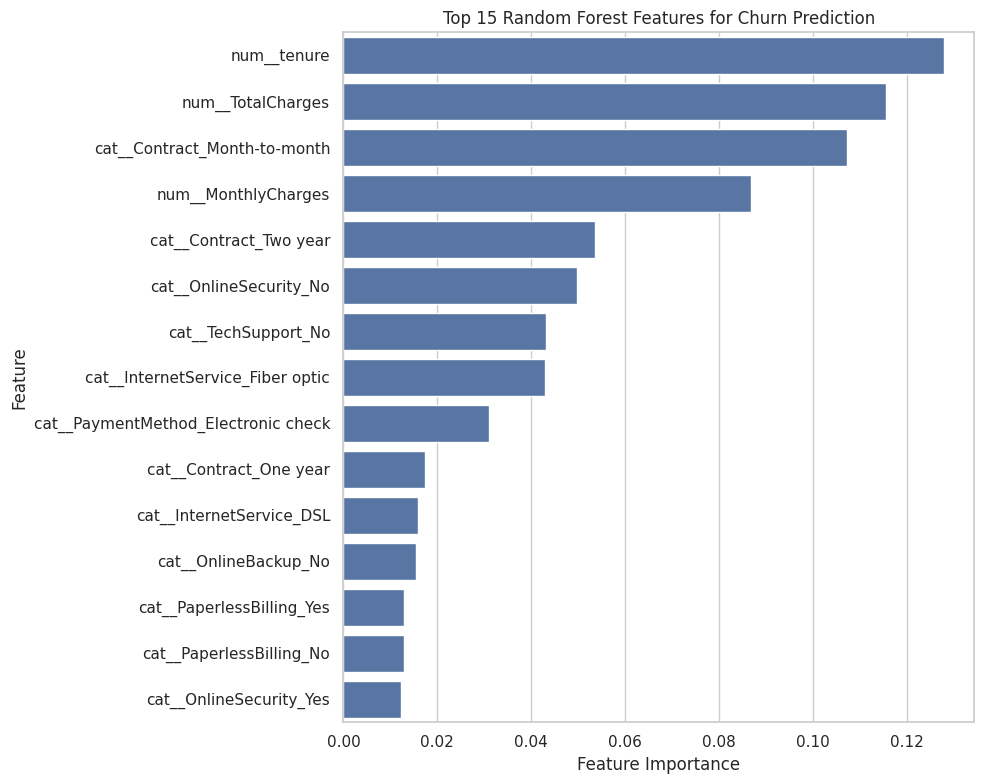

In [25]:
# Random Forest feature importance is used to identify variables
# contributing most strongly to the model's predictive decisions.

rf_pipeline = fitted_models["Random Forest"]

# Extract transformed feature names
preprocessor_fitted = rf_pipeline.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()
rf_model = rf_pipeline.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Random Forest Features for Churn Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 11.1 Permutation Importance on the Test Set

,Feature,Mean Importance,Std Importance
14,Contract,0.063661,0.006338
4,tenure,0.028621,0.003996
7,InternetService,0.017990,0.003732
18,TotalCharges,0.011344,0.002181
8,OnlineSecurity,0.003388,0.002355
16,PaymentMethod,0.002267,0.002861
11,TechSupport,0.001227,0.002640
5,PhoneService,0.000615,0.000451
0,gender,0.000272,0.001149
1,SeniorCitizen,0.000226,0.000533


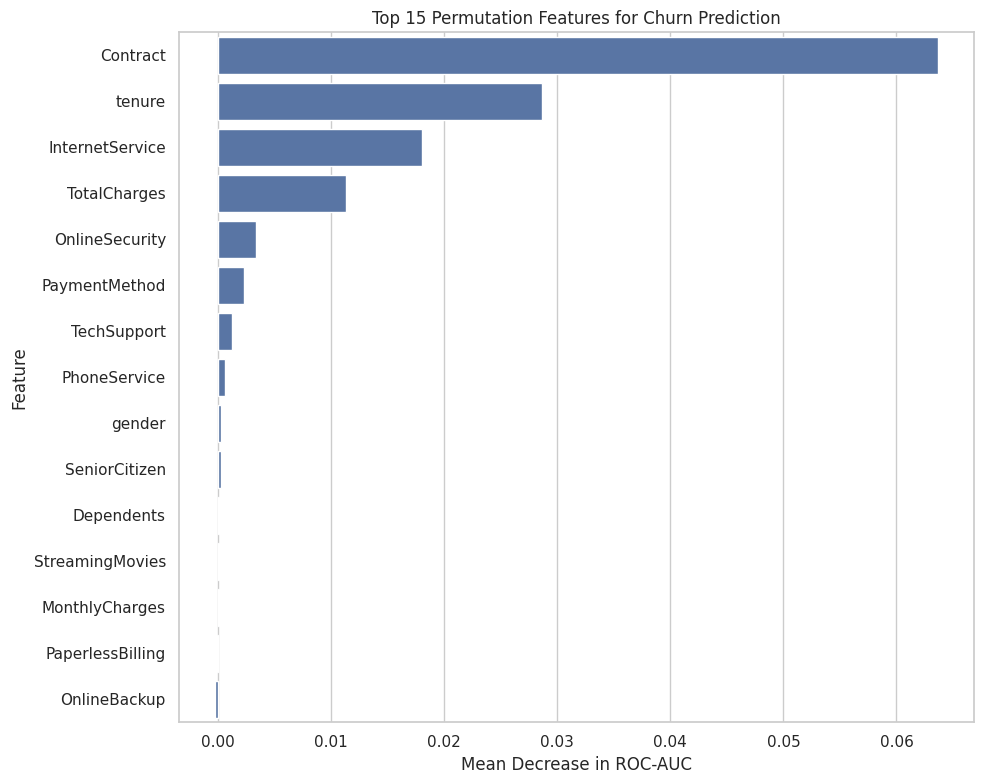

In [26]:
# Permutation importance provides an additional model-agnostic interpretation.
# It measures the reduction in model performance when a feature is shuffled.

rf_perm = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Use original input features for easier interpretation
perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Importance": rf_perm.importances_mean,
    "Std Importance": rf_perm.importances_std
}).sort_values("Mean Importance", ascending=False)

display(perm_df.head(15))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=perm_df.head(15),
    x="Mean Importance",
    y="Feature"
)
plt.title("Top 15 Permutation Features for Churn Prediction")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 12. Model Performance Visualisation

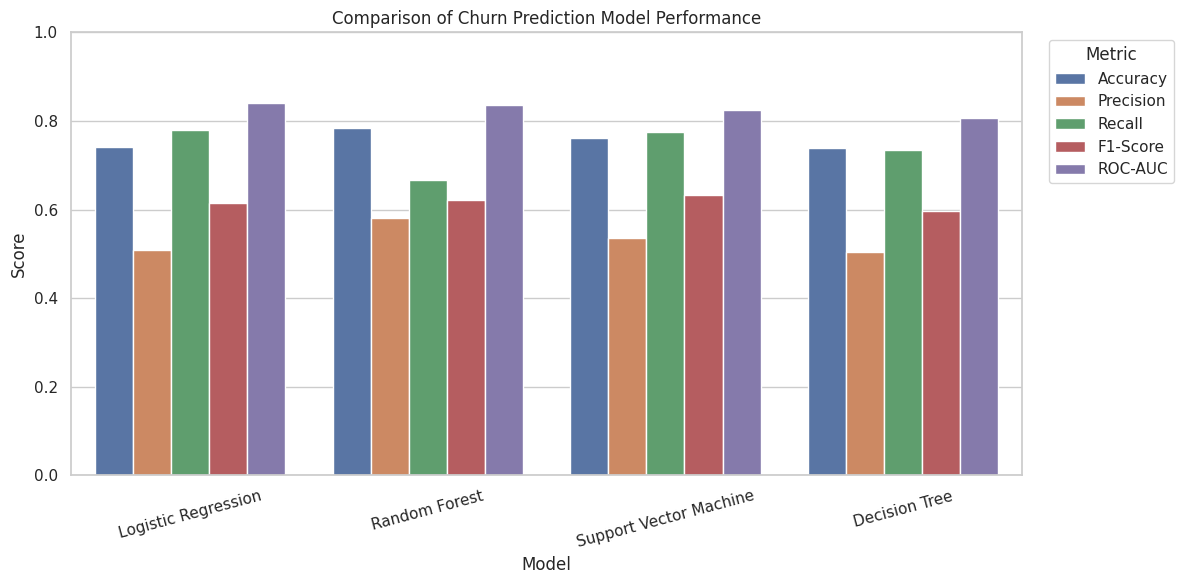

In [27]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)
plt.title("Comparison of Churn Prediction Model Performance")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 13. SHAP Explainability

In [28]:
# Install SHAP
!pip install shap -q

import shap

In [29]:
# Select the fitted Random Forest pipeline
rf_pipeline = fitted_models["Random Forest"]

# Extract preprocessing and Random Forest classifier
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_classifier = rf_pipeline.named_steps["classifier"]

# Transform the test data
X_test_transformed = rf_preprocessor.transform(X_test)

# Convert sparse matrix to dense format
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Get transformed feature names
shap_feature_names = rf_preprocessor.get_feature_names_out()

# Create DataFrame for SHAP
X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=shap_feature_names,
    index=X_test.index
)

print("SHAP data shape:", X_test_shap.shape)

SHAP data shape: (1405, 45)


In [30]:
# Create Tree SHAP explainer
explainer = shap.TreeExplainer(rf_classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_shap)

# Select churn class
if isinstance(shap_values, list):
    shap_churn = shap_values[1]
else:
    shap_churn = shap_values

print("SHAP values calculated successfully.")
print("SHAP value shape:", np.array(shap_churn).shape)

SHAP values calculated successfully.
SHAP value shape: (1405, 45, 2)


In [31]:
# Create Tree SHAP explainer
explainer = shap.TreeExplainer(rf_classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_shap)

# Select churn class
if isinstance(shap_values, list):
    shap_churn = shap_values[1]
else:
    shap_churn = shap_values

print("SHAP values calculated successfully.")
print("SHAP value shape:", np.array(shap_churn).shape)

SHAP values calculated successfully.
SHAP value shape: (1405, 45, 2)


In [32]:
# Calculate mean absolute SHAP value

# Handle different SHAP output formats
if shap_churn.ndim == 3:
    # Select the Churn class (class 1)
    shap_churn_2d = shap_churn[:, :, 1]
else:
    shap_churn_2d = shap_churn

shap_importance = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean Absolute SHAP": np.abs(shap_churn_2d).mean(axis=0)
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(shap_importance.head(20))

,Feature,Mean Absolute SHAP
36,cat__Contract_Month-to-month,0.071491
1,num__tenure,0.060101
16,cat__InternetService_Fiber optic,0.043274
3,num__TotalCharges,0.037891
38,cat__Contract_Two year,0.034691
18,cat__OnlineSecurity_No,0.033357
27,cat__TechSupport_No,0.027512
2,num__MonthlyCharges,0.025047
43,cat__PaymentMethod_Electronic check,0.024376
15,cat__InternetService_DSL,0.017450


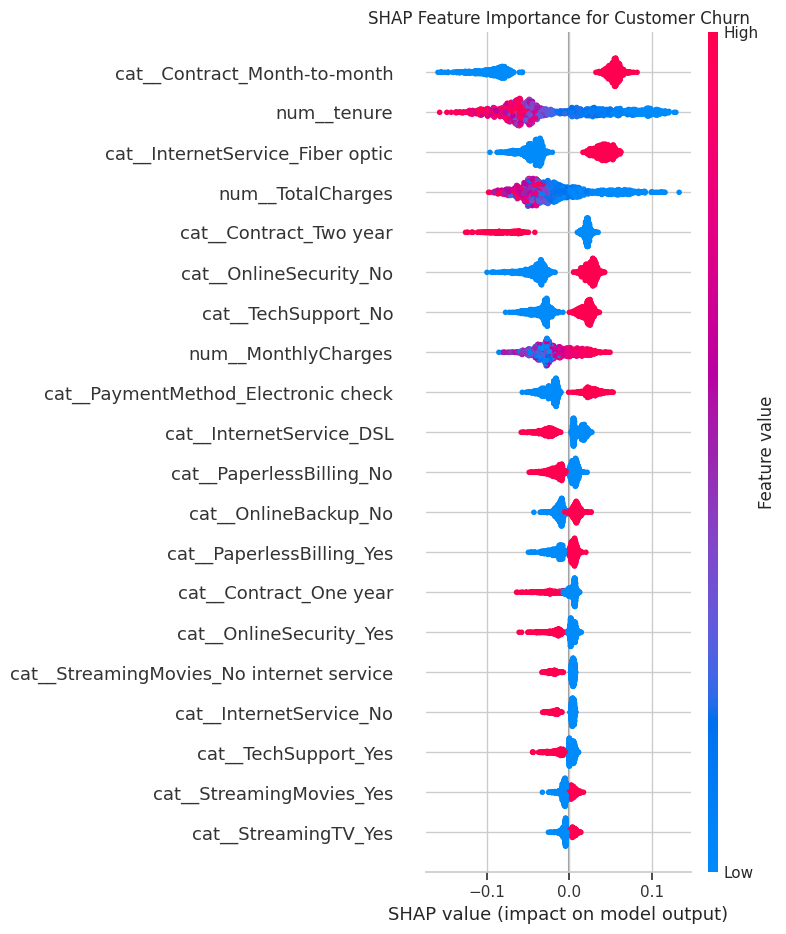

In [33]:
plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_churn_2d,
    X_test_shap,
    feature_names=shap_feature_names,
    show=False
)

plt.title("SHAP Feature Importance for Customer Churn")
plt.tight_layout()
plt.show()

## 14. LIME Explainability

In [34]:
# Install LIME
!pip install lime -q

from lime.lime_tabular import LimeTabularExplainer

In [35]:
# Transform training data using the same Random Forest preprocessing
X_train_transformed = rf_preprocessor.transform(X_train)

# Convert sparse matrix to dense format
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

# Create DataFrame
X_train_lime = pd.DataFrame(
    X_train_transformed,
    columns=shap_feature_names
)

print("LIME training data shape:", X_train_lime.shape)

LIME training data shape: (5616, 45)


In [36]:
lime_explainer = LimeTabularExplainer(
    X_train_lime.values,
    feature_names=shap_feature_names,
    class_names=["No Churn", "Churn"],
    mode="classification",
    random_state=RANDOM_STATE
)

print("LIME explainer created successfully.")

LIME explainer created successfully.


In [37]:
def lime_predict_proba(transformed_data):
    return rf_classifier.predict_proba(transformed_data)

In [38]:
# Select the same customer used for SHAP
customer_position = 0

lime_explanation = lime_explainer.explain_instance(
    X_test_shap.iloc[customer_position].values,
    lime_predict_proba,
    num_features=10
)

lime_results = pd.DataFrame(
    lime_explanation.as_list(),
    columns=["Feature", "Contribution"]
)

display(lime_results)

,Feature,Contribution
0,0.00 < cat__Contract_Month-to-month <= 1.00,0.109393
1,num__tenure <= -0.96,0.094789
2,cat__Contract_Two year <= 0.00,0.077247
3,0.00 < cat__InternetService_Fiber optic <= 1.00,0.072189
4,cat__InternetService_DSL <= 0.00,0.036797
5,0.00 < cat__OnlineSecurity_No <= 1.00,0.034723
6,0.00 < cat__PaymentMethod_Electronic check <= ...,0.032555
7,cat__StreamingMovies_No internet service <= 0.00,0.023597
8,0.00 < cat__TechSupport_No <= 1.00,0.021577
9,cat__PaperlessBilling_No <= 0.00,0.017602


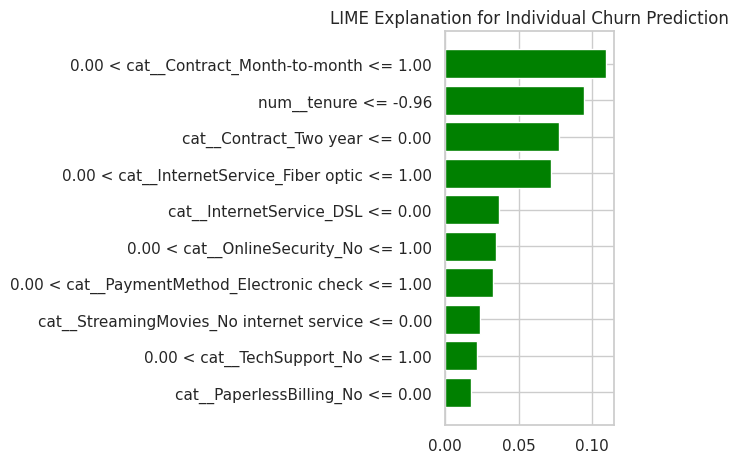

In [39]:
fig = lime_explanation.as_pyplot_figure()

plt.title("LIME Explanation for Individual Churn Prediction")
plt.tight_layout()
plt.show()

## 15. Customer Churn Risk Scoring

Sample Customer Churn Probabilities:


,Churn_Probability
0,0.614168
1,0.024540
2,0.701827
3,0.040118
4,0.846849
5,0.943574
6,0.617182
7,0.340732
8,0.815797
9,0.056372


Sample Customer Risk Categories:


,Churn_Probability,Risk_Category
0,0.614168,High Risk
1,0.024540,Low Risk
2,0.701827,High Risk
3,0.040118,Low Risk
4,0.846849,High Risk
5,0.943574,High Risk
6,0.617182,High Risk
7,0.340732,Medium Risk
8,0.815797,High Risk
9,0.056372,Low Risk


Customer Churn Risk Distribution:


,Customers,Percentage
Risk_Category,,
Low Risk,3772,53.72
Medium Risk,1398,19.91
High Risk,1851,26.36


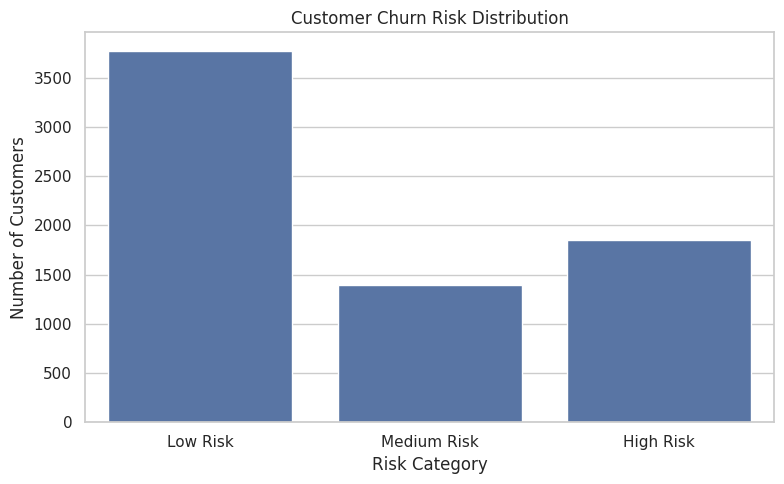

Number of high-risk customers: 1851

Contract Distribution Among High-Risk Customers:


,Customers
Contract,
Month-to-month,1815
One year,34
Two year,2



Average Monthly Charges Among High-Risk Customers:
76.69

Average Tenure Among High-Risk Customers:
12.98

Top 10 Highest-Risk Customers:


,Churn_Probability,Risk_Category,Contract,tenure,MonthlyCharges,TotalCharges
6467,0.965226,High Risk,Month-to-month,1,101.45,101.45
6845,0.962057,High Risk,Month-to-month,1,95.45,95.45
3202,0.960439,High Risk,Month-to-month,1,93.85,93.85
2572,0.960348,High Risk,Month-to-month,1,94.60,94.60
1971,0.960222,High Risk,Month-to-month,1,93.55,93.55
4789,0.960222,High Risk,Month-to-month,1,94.00,94.00
4202,0.954576,High Risk,Month-to-month,1,90.60,90.60
982,0.953452,High Risk,Month-to-month,1,86.60,86.60
968,0.953440,High Risk,Month-to-month,2,96.00,174.80
969,0.953408,High Risk,Month-to-month,1,90.55,90.55


In [40]:

# 15.1 Prepare all predictor variables
X_all = data.drop(columns=[target])

# Generate churn probabilities using the trained Random Forest model
rf_all_probabilities = fitted_models["Random Forest"].predict_proba(
    X_all
)[:, 1]

# Create a risk dataframe
risk_df = data.copy()

# Add predicted churn probability
risk_df["Churn_Probability"] = rf_all_probabilities

# Display sample churn probabilities
print("Sample Customer Churn Probabilities:")
display(
    risk_df[
        ["Churn_Probability"]
    ].head(10)
)


# 15.2 Create churn risk categories

risk_df["Risk_Category"] = pd.cut(
    risk_df["Churn_Probability"],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

print("Sample Customer Risk Categories:")
display(
    risk_df[
        ["Churn_Probability", "Risk_Category"]
    ].head(10)
)


# 15.3 Calculate risk distribution

risk_summary = (
    risk_df["Risk_Category"]
    .value_counts()
    .reindex(
        ["Low Risk", "Medium Risk", "High Risk"]
    )
    .fillna(0)
    .to_frame("Customers")
)

risk_summary["Percentage"] = (
    risk_summary["Customers"] /
    len(risk_df) * 100
)

print("Customer Churn Risk Distribution:")
display(risk_summary.round(2))


# 15.4 Visualise risk distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_df,
    x="Risk_Category",
    order=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


# 15.5 Analyse high-risk customers

high_risk = risk_df[
    risk_df["Risk_Category"] == "High Risk"
].copy()

print("Number of high-risk customers:", len(high_risk))


# Contract distribution
if "Contract" in high_risk.columns:

    print("\nContract Distribution Among High-Risk Customers:")

    display(
        high_risk["Contract"]
        .value_counts()
        .to_frame("Customers")
    )


# Average monthly charges
if "MonthlyCharges" in high_risk.columns:

    print("\nAverage Monthly Charges Among High-Risk Customers:")

    print(
        round(
            high_risk["MonthlyCharges"].mean(),
            2
        )
    )


# Average tenure
if "tenure" in high_risk.columns:

    print("\nAverage Tenure Among High-Risk Customers:")

    print(
        round(
            high_risk["tenure"].mean(),
            2
        )
    )


# Display highest-risk customers
print("\nTop 10 Highest-Risk Customers:")

display(
    risk_df[
        [
            "Churn_Probability",
            "Risk_Category",
            "Contract",
            "tenure",
            "MonthlyCharges",
            "TotalCharges"
        ]
    ]
    .sort_values(
        "Churn_Probability",
        ascending=False
    )
    .head(10)
)

## 16. Retention Priority Matrix

Historical Customer Value Cut-off:
1400.55
Retention Priority Distribution:


,Customers,Percentage
Retention_Priority,,
Low Priority,3772,53.72
Medium Priority,1398,19.91
Monitor High Risk,1343,19.13
Priority Retention,508,7.24


Customer Risk and Historical Value Matrix:


Customer_Value_Category,Lower Historical Value,Higher Historical Value
Risk_Category,,
Low Risk,1526,2246
Medium Risk,641,757
High Risk,1343,508


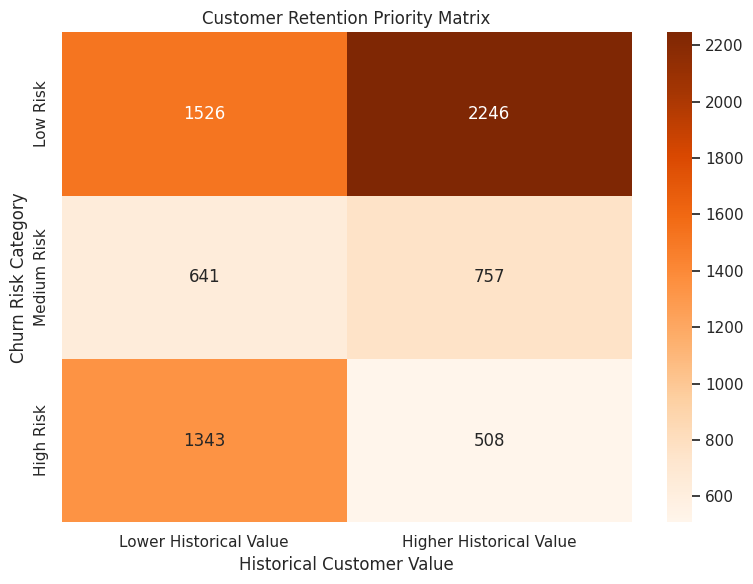

Number of customers classified as Priority Retention: 508

Top Priority Retention Customers:


,Churn_Probability,Risk_Category,Customer_Value_Category,Retention_Priority,Contract,tenure,MonthlyCharges,TotalCharges
1237,0.908414,High Risk,Higher Historical Value,Priority Retention,Month-to-month,16,96.15,1529.20
2443,0.886981,High Risk,Higher Historical Value,Priority Retention,Month-to-month,14,104.85,1531.40
2511,0.882758,High Risk,Higher Historical Value,Priority Retention,Month-to-month,16,96.40,1581.20
2941,0.876748,High Risk,Higher Historical Value,Priority Retention,Month-to-month,41,99.80,4259.30
755,0.876110,High Risk,Higher Historical Value,Priority Retention,Month-to-month,20,98.55,1842.80
948,0.875307,High Risk,Higher Historical Value,Priority Retention,Month-to-month,35,99.05,3395.80
3766,0.873990,High Risk,Higher Historical Value,Priority Retention,Month-to-month,41,98.40,4187.75
1483,0.868884,High Risk,Higher Historical Value,Priority Retention,Month-to-month,22,96.70,2082.95
4010,0.868558,High Risk,Higher Historical Value,Priority Retention,Month-to-month,14,100.55,1415.55
1080,0.868324,High Risk,Higher Historical Value,Priority Retention,Month-to-month,46,98.85,4564.90


In [41]:

# 16.1 Create customer value categories
# TotalCharges is used as a historical customer-value proxy.
value_cutoff = risk_df["TotalCharges"].median()

risk_df["Customer_Value_Category"] = np.where(
    risk_df["TotalCharges"] >= value_cutoff,
    "Higher Historical Value",
    "Lower Historical Value"
)

print("Historical Customer Value Cut-off:")
print(round(value_cutoff, 2))


# 16.2 Create retention priority categories

def assign_retention_priority(row):

    if (
        row["Risk_Category"] == "High Risk"
        and row["Customer_Value_Category"] == "Higher Historical Value"
    ):
        return "Priority Retention"

    elif (
        row["Risk_Category"] == "High Risk"
        and row["Customer_Value_Category"] == "Lower Historical Value"
    ):
        return "Monitor High Risk"

    elif row["Risk_Category"] == "Medium Risk":
        return "Medium Priority"

    else:
        return "Low Priority"


risk_df["Retention_Priority"] = risk_df.apply(
    assign_retention_priority,
    axis=1
)


# 16.3 Display retention priority distribution

priority_summary = (
    risk_df["Retention_Priority"]
    .value_counts()
    .to_frame("Customers")
)

priority_summary["Percentage"] = (
    priority_summary["Customers"]
    / len(risk_df)
    * 100
)

print("Retention Priority Distribution:")

display(
    priority_summary.round(2)
)


# 16.4 Create risk and customer-value matrix

retention_matrix = pd.crosstab(
    risk_df["Risk_Category"],
    risk_df["Customer_Value_Category"]
)

retention_matrix = retention_matrix.reindex(
    index=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ],
    columns=[
        "Lower Historical Value",
        "Higher Historical Value"
    ],
    fill_value=0
)

print("Customer Risk and Historical Value Matrix:")

display(retention_matrix)


# 16.5 Visualise retention priority matrix

plt.figure(figsize=(8, 6))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Customer Retention Priority Matrix")
plt.xlabel("Historical Customer Value")
plt.ylabel("Churn Risk Category")

plt.tight_layout()
plt.show()


# 16.6 Display priority-retention customers

priority_customers = risk_df[
    risk_df["Retention_Priority"] == "Priority Retention"
].copy()

print(
    "Number of customers classified as Priority Retention:",
    len(priority_customers)
)


# 16.7 Display highest-risk, higher-value customers

print(
    "\nTop Priority Retention Customers:"
)

display(
    priority_customers[
        [
            "Churn_Probability",
            "Risk_Category",
            "Customer_Value_Category",
            "Retention_Priority",
            "Contract",
            "tenure",
            "MonthlyCharges",
            "TotalCharges"
        ]
    ]
    .sort_values(
        "Churn_Probability",
        ascending=False
    )
    .head(10)
)

## 17. Feature-Group Analysis


Processing: Demographic Features

Processing: Service Features

Processing: Account Features

Processing: All Features

Feature Group Model Performance:


,Feature Group,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Demographic Features,0.559,0.339,0.699,0.457,0.637
1,Service Features,0.698,0.456,0.731,0.562,0.757
2,Account Features,0.764,0.544,0.669,0.600,0.828
3,All Features,0.784,0.581,0.667,0.621,0.837


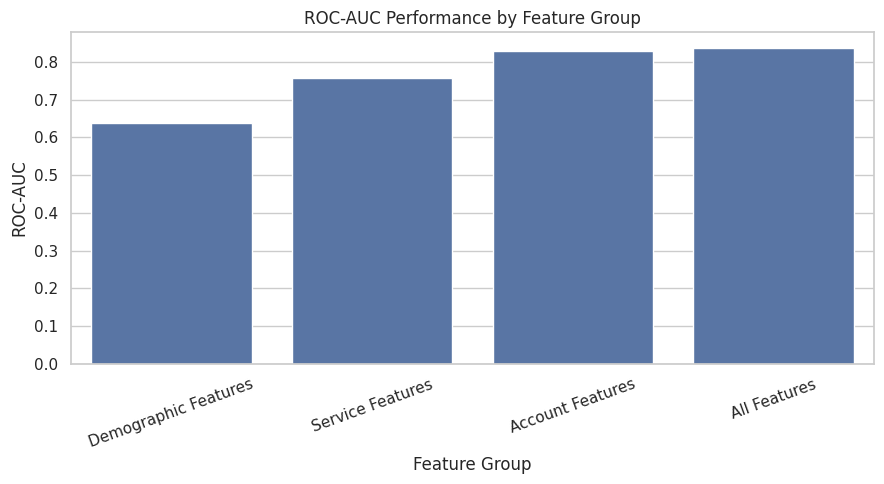

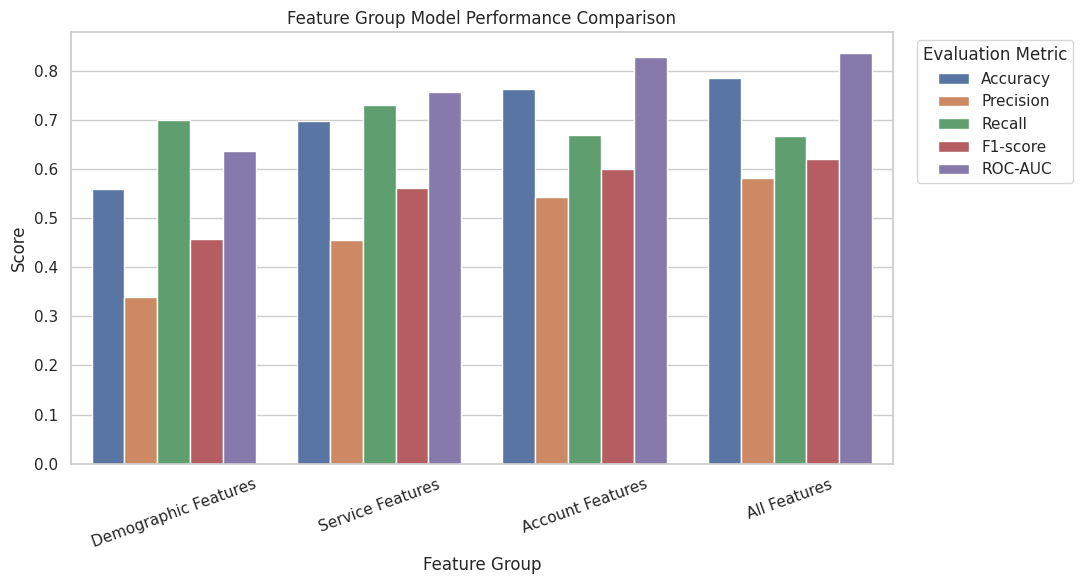


Feature Group with Highest ROC-AUC:
Feature Group    All Features
ROC-AUC              0.836507
Accuracy             0.784342
Precision            0.580796
Recall               0.666667
F1-score             0.620776
Name: 3, dtype: object


In [42]:
# Define feature groups
feature_groups = {

    "Demographic Features": [
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents"
    ],

    "Service Features": [
        "PhoneService",
        "MultipleLines",
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ],

    "Account Features": [
        "tenure",
        "Contract",
        "PaperlessBilling",
        "PaymentMethod",
        "MonthlyCharges",
        "TotalCharges"
    ],

    "All Features": X_all.columns.tolist()
}


# 17.1 Train Random Forest models for each feature group

feature_group_results = []

for group_name, features in feature_groups.items():

    print(f"\nProcessing: {group_name}")

    # Select only the features in the current group
    X_group = X_all[features].copy()

    # Stratified train-test split
    X_group_train, X_group_test, y_group_train, y_group_test = train_test_split(
        X_group,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )

    # Identify numerical and categorical features
    group_numeric_features = X_group.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    group_categorical_features = X_group.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    # Numerical preprocessing
    group_numeric_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    # Categorical preprocessing
    group_categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]
    )

    # Combined preprocessing
    group_preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                group_numeric_pipeline,
                group_numeric_features
            ),
            (
                "cat",
                group_categorical_pipeline,
                group_categorical_features
            )
        ],
        remainder="drop"
    )

    # Random Forest model
    group_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Complete pipeline
    group_pipeline = Pipeline(
        steps=[
            ("preprocessor", group_preprocessor),
            ("classifier", group_model)
        ]
    )

    # Train model
    group_pipeline.fit(
        X_group_train,
        y_group_train
    )

    # Predict classes and probabilities
    group_predictions = group_pipeline.predict(
        X_group_test
    )

    group_probabilities = group_pipeline.predict_proba(
        X_group_test
    )[:, 1]

    # Calculate evaluation metrics
    group_accuracy = accuracy_score(
        y_group_test,
        group_predictions
    )

    group_precision = precision_score(
        y_group_test,
        group_predictions,
        zero_division=0
    )

    group_recall = recall_score(
        y_group_test,
        group_predictions,
        zero_division=0
    )

    group_f1 = f1_score(
        y_group_test,
        group_predictions,
        zero_division=0
    )

    group_roc_auc = roc_auc_score(
        y_group_test,
        group_probabilities
    )

    # Store results
    feature_group_results.append({
        "Feature Group": group_name,
        "Accuracy": group_accuracy,
        "Precision": group_precision,
        "Recall": group_recall,
        "F1-score": group_f1,
        "ROC-AUC": group_roc_auc
    })


# 17.2 Create feature-group performance table

feature_group_results_df = pd.DataFrame(
    feature_group_results
)

print("\nFeature Group Model Performance:")

display(
    feature_group_results_df.round(3)
)


# 17.3 Plot ROC-AUC comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_group_results_df,
    x="Feature Group",
    y="ROC-AUC"
)

plt.title("ROC-AUC Performance by Feature Group")
plt.xlabel("Feature Group")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


# 17.4 Plot all evaluation metrics

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

feature_group_long = feature_group_results_df.melt(
    id_vars="Feature Group",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=feature_group_long,
    x="Feature Group",
    y="Score",
    hue="Metric"
)

plt.title("Feature Group Model Performance Comparison")
plt.xlabel("Feature Group")
plt.ylabel("Score")
plt.xticks(rotation=20)

plt.legend(
    title="Evaluation Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# 17.5 Identify the highest-performing feature group

best_feature_group = feature_group_results_df.loc[
    feature_group_results_df["ROC-AUC"].idxmax()
]

print("\nFeature Group with Highest ROC-AUC:")
print(
    best_feature_group[
        [
            "Feature Group",
            "ROC-AUC",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score"
        ]
    ].round(3)
)